# EuroSAT RGB — Federated Data Analysis

## 1. Introduction

This notebook analyzes the EuroSAT RGB dataset used in our federated learning experiments.

The objective is to understand:
- The original dataset characteristics and class distribution.
- The distribution of data across five federated clients.
- The quantity and statistical heterogeneity between clients.
- The differences between local and centralized evaluation datasets.

## Experimental Configuration

| Parameter | Value |
|---|---|
| Dataset | EuroSAT RGB |
| Number of clients | 5 |
| Partitioning method | Dirichlet |
| Dirichlet concentration (α) | 0.1 |
| Random seed | 42 |
| Local training/validation split | 80% / 20% |
| Model | MobileNetV2 |
| Training approach | From scratch |

## 2. Environment and Imports

We import the libraries required for dataset loading, statistical analysis, 
data manipulation and visualization.

We also reuse the dataset configuration and partitioning function defined 
in the Flower project to ensure consistency with the federated learning experiments.

In [1]:
# Standard libraries
from collections import Counter
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Dataset handling
from datasets import load_dataset
from flwr_datasets import FederatedDataset

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Reuse the actual Flower project configuration
from pytorchexample.task import (
    DATASET_NAME,
    BASE_SEED,
    create_partitioner,
    shuffle_train_split,
)

# Experimental configuration
NUM_CLIENTS = 5
ALPHA = 0.1
SEED = BASE_SEED

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)

sns.set_theme(style="whitegrid")

print("Imports completed successfully.")
print(f"Dataset: {DATASET_NAME}")
print(f"Number of clients: {NUM_CLIENTS}")
print(f"Dirichlet alpha: {ALPHA}")
print(f"Random seed: {SEED}")

f:\Flower\quickstart-pytorch\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports completed successfully.
Dataset: blanchon/EuroSAT_RGB
Number of clients: 5
Dirichlet alpha: 0.1
Random seed: 42


## 3. Original Dataset Overview

We first load the original EuroSAT RGB dataset.

EuroSAT is a land-use and land-cover image classification dataset 
containing satellite images belonging to ten different land-cover classes.

The dataset provides three predefined splits:
- Training
- Validation
- Test

We will inspect their sizes and class distributions before applying 
federated partitioning.

In [2]:
# Load the three predefined dataset splits
train_dataset = load_dataset(DATASET_NAME, split="train")
validation_dataset = load_dataset(DATASET_NAME, split="validation")
test_dataset = load_dataset(DATASET_NAME, split="test")

# Extract class names
class_names = train_dataset.features["label"].names
NUM_CLASSES = len(class_names)

print("Dataset loaded successfully.")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Class names: {class_names}")

Dataset loaded successfully.
Number of classes: 10
Class names: ['Annual Crop', 'Forest', 'Herbaceous Vegetation', 'Highway', 'Industrial Buildings', 'Pasture', 'Permanent Crop', 'Residential Buildings', 'River', 'SeaLake']


In [3]:
# Load the three predefined dataset splits
train_dataset = load_dataset(DATASET_NAME, split="train")
validation_dataset = load_dataset(DATASET_NAME, split="validation")
test_dataset = load_dataset(DATASET_NAME, split="test")

# Extract class names
class_names = train_dataset.features["label"].names
NUM_CLASSES = len(class_names)

print("Dataset loaded successfully.")
print(f"Number of classes: {NUM_CLASSES}")
print(f"Class names: {class_names}")

Dataset loaded successfully.
Number of classes: 10
Class names: ['Annual Crop', 'Forest', 'Herbaceous Vegetation', 'Highway', 'Industrial Buildings', 'Pasture', 'Permanent Crop', 'Residential Buildings', 'River', 'SeaLake']


### 3.1 Class Distribution in the Original Dataset

We examine the number of samples belonging to each class.

This allows us to determine whether the original dataset is balanced 
or whether some classes are naturally more represented than others.

This distinction is important because we want to separate the original 
dataset imbalance from the additional heterogeneity introduced by 
federated partitioning.

In [4]:
# Count samples for every class in each split
original_class_distribution = pd.DataFrame({
    "Class": class_names,
    "Training": [
        Counter(train_dataset["label"]).get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Validation": [
        Counter(validation_dataset["label"]).get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Test": [
        Counter(test_dataset["label"]).get(i, 0)
        for i in range(NUM_CLASSES)
    ],
})

display(original_class_distribution)

,Class,Training,Validation,Test
0,Annual Crop,1791,613,596
1,Forest,1787,605,608
2,Herbaceous Vegetation,1799,628,573
3,Highway,1505,499,496
4,Industrial Buildings,1492,507,501
5,Pasture,1195,409,396
6,Permanent Crop,1481,481,538
7,Residential Buildings,1863,583,554
8,River,1460,511,529
9,SeaLake,1827,564,609


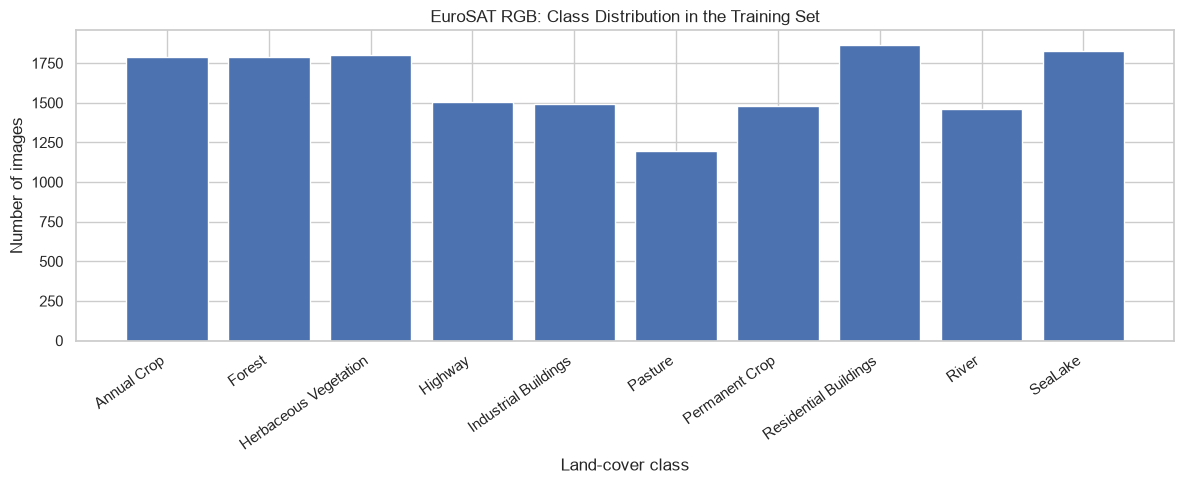

In [5]:
plt.figure(figsize=(12, 5))

plt.bar(
    original_class_distribution["Class"],
    original_class_distribution["Training"],
)

plt.title("EuroSAT RGB: Class Distribution in the Training Set")
plt.xlabel("Land-cover class")
plt.ylabel("Number of images")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

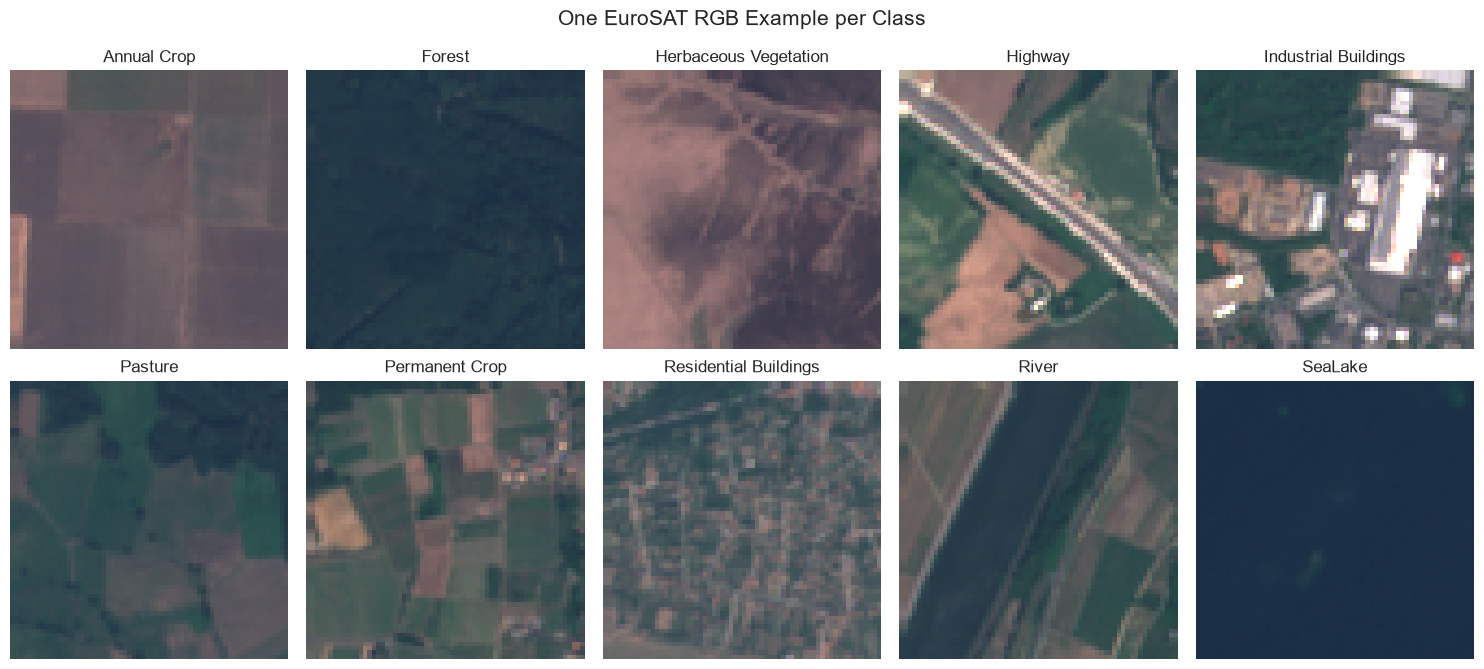

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for class_id, ax in enumerate(axes.flat):

    # Find one image belonging to this class
    index = next(
        i for i, label in enumerate(train_dataset["label"])
        if label == class_id
    )

    sample = train_dataset[index]

    ax.imshow(sample["image"])
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.suptitle("One EuroSAT RGB Example per Class", fontsize=15)
plt.tight_layout()
plt.show()

### 3.2 Federated Data Partitioning

We now distribute the original training dataset across five
federated clients using a Dirichlet partitioning strategy.

The concentration parameter α controls the degree of
statistical heterogeneity between clients.

A small α value (0.1) encourages highly non-IID distributions,
where clients may have very different class proportions.

We use the same partitioning function and random seed as
the Flower simulation to ensure consistency.

In [7]:
# Create the federated dataset using the project's configuration
partitioner = create_partitioner(NUM_CLIENTS)

fds = FederatedDataset(
    dataset=DATASET_NAME,
    partitioners={"train": partitioner},
    shuffle=False,
    preprocessor=shuffle_train_split,
)

# Load the partition assigned to each client
client_partitions = [
    fds.load_partition(partition_id=i)
    for i in range(NUM_CLIENTS)
]

print("Federated partitions loaded successfully.")

Federated partitions loaded successfully.


In [8]:
client_sizes = pd.DataFrame({
    "Client": [f"Client {i}" for i in range(NUM_CLIENTS)],
    "Number of samples": [
        len(partition)
        for partition in client_partitions
    ],
})

client_sizes["Percentage (%)"] = (
    client_sizes["Number of samples"]
    / sum(client_sizes["Number of samples"])
    * 100
)

display(client_sizes.round(2))

print(
    "Total samples across clients:",
    client_sizes["Number of samples"].sum()
)

,Client,Number of samples,Percentage (%)
0,Client 0,2844,17.56
1,Client 1,8518,52.58
2,Client 2,2037,12.57
3,Client 3,990,6.11
4,Client 4,1811,11.18


Total samples across clients: 16200


In [9]:
client_class_distribution = pd.DataFrame(
    {
        f"Client {i}": [
            Counter(client_partitions[i]["label"]).get(class_id, 0)
            for class_id in range(NUM_CLASSES)
        ]
        for i in range(NUM_CLIENTS)
    },
    index=class_names,
)

client_class_distribution.index.name = "Class"

display(client_class_distribution)

,Client 0,Client 1,Client 2,Client 3,Client 4
Class,,,,,
Annual Crop,383,1083,0,324,1
Forest,0,132,3,30,1622
Herbaceous Vegetation,80,1613,105,0,1
Highway,1489,1,14,0,1
Industrial Buildings,1,202,1132,1,156
Pasture,0,892,298,4,1
Permanent Crop,758,142,453,127,1
Residential Buildings,0,1837,0,0,26
River,133,1018,0,308,1


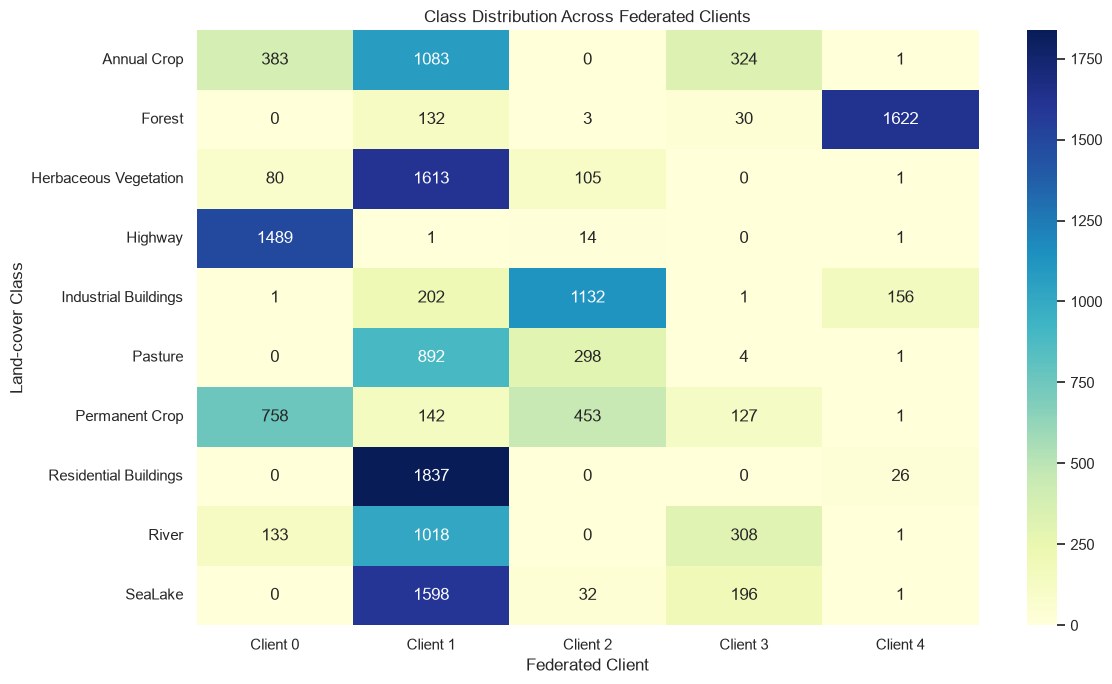

In [10]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    client_class_distribution,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
)

plt.title("Class Distribution Across Federated Clients")
plt.xlabel("Federated Client")
plt.ylabel("Land-cover Class")

plt.tight_layout()
plt.show()

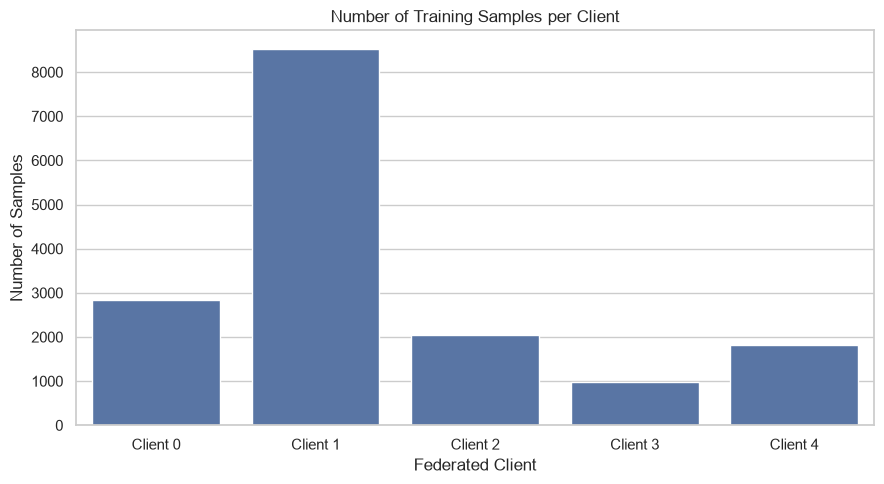

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=client_sizes,
    x="Client",
    y="Number of samples",
)

plt.title("Number of Training Samples per Client")
plt.xlabel("Federated Client")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [12]:
# Calculate class proportions within each client
client_class_proportions = (
    client_class_distribution
    .div(client_class_distribution.sum(axis=0), axis=1)
    * 100
)

display(client_class_proportions.round(2))

,Client 0,Client 1,Client 2,Client 3,Client 4
Class,,,,,
Annual Crop,13.47,12.71,0.00,32.73,0.06
Forest,0.00,1.55,0.15,3.03,89.56
Herbaceous Vegetation,2.81,18.94,5.15,0.00,0.06
Highway,52.36,0.01,0.69,0.00,0.06
Industrial Buildings,0.04,2.37,55.57,0.10,8.61
Pasture,0.00,10.47,14.63,0.40,0.06
Permanent Crop,26.65,1.67,22.24,12.83,0.06
Residential Buildings,0.00,21.57,0.00,0.00,1.44
River,4.68,11.95,0.00,31.11,0.06


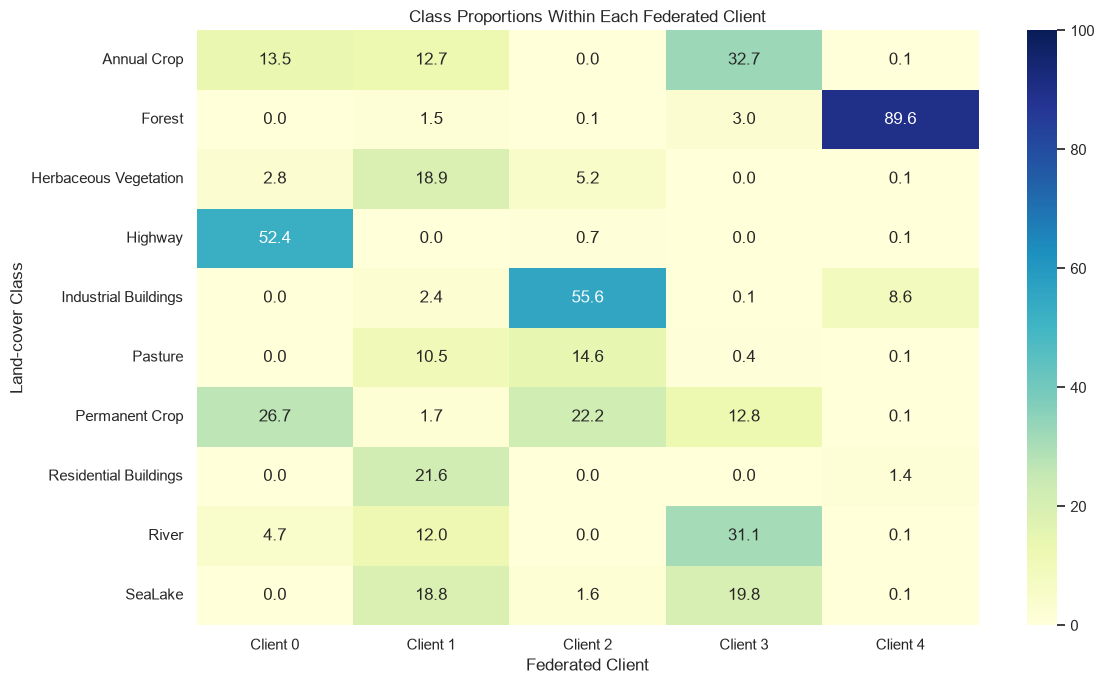

In [13]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    client_class_proportions,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
)

plt.title("Class Proportions Within Each Federated Client")
plt.xlabel("Federated Client")
plt.ylabel("Land-cover Class")

plt.tight_layout()
plt.show()

In [15]:
# Calculate Shannon entropy for each client

client_entropy = {}

for client in client_class_proportions.columns:
    proportions = (
        client_class_proportions[client].to_numpy() / 100
    )

    # Ignore zero probabilities (log(0) is undefined)
    nonzero = proportions[proportions > 0]

    entropy = -np.sum(nonzero * np.log(nonzero))
    normalized_entropy = entropy / np.log(NUM_CLASSES)

    client_entropy[client] = {
        "Entropy": entropy,
        "Normalized Entropy": normalized_entropy,
        "Number of classes": np.sum(proportions > 0),
    }

entropy_df = pd.DataFrame(client_entropy).T

display(entropy_df.round(3))

,Entropy,Normalized Entropy,Number of classes
Client 0,1.208,0.524,6.0
Client 1,1.935,0.840,10.0
Client 2,1.204,0.523,7.0
Client 3,1.448,0.629,7.0
Client 4,0.400,0.174,10.0


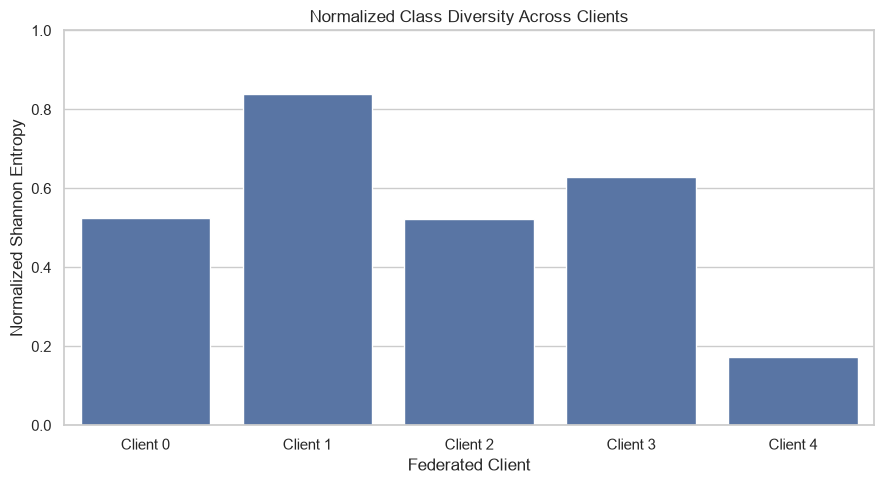

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=entropy_df.reset_index(),
    x="index",
    y="Normalized Entropy",
)

plt.ylim(0, 1)
plt.title("Normalized Class Diversity Across Clients")
plt.xlabel("Federated Client")
plt.ylabel("Normalized Shannon Entropy")

plt.tight_layout()
plt.show()

In [17]:
from pytorchexample.resources import CLIENT_PROFILES

client_profile = client_sizes.copy()

client_profile["Compute capacity"] = [
    CLIENT_PROFILES[i]["compute_capacity"]
    for i in range(NUM_CLIENTS)
]

client_profile["Delay per batch (ms)"] = [
    CLIENT_PROFILES[i]["compute_delay_per_batch"] * 1000
    for i in range(NUM_CLIENTS)
]

client_profile["Availability (%)"] = [
    CLIENT_PROFILES[i]["availability"] * 100
    for i in range(NUM_CLIENTS)
]

client_profile["Normalized entropy"] = (
    entropy_df["Normalized Entropy"].values
)

client_profile["Number of classes"] = (
    entropy_df["Number of classes"].values
)

display(client_profile.round(2))

,Client,Number of samples,Percentage (%),Compute capacity,Delay per batch (ms),Availability (%),Normalized entropy,Number of classes
0,Client 0,2844,17.56,high,0.0,100.0,0.52,6.0
1,Client 1,8518,52.58,medium,5.0,100.0,0.84,10.0
2,Client 2,2037,12.57,low,15.0,100.0,0.52,7.0
3,Client 3,990,6.11,very_low,25.0,80.0,0.63,7.0
4,Client 4,1811,11.18,medium,5.0,60.0,0.17,10.0


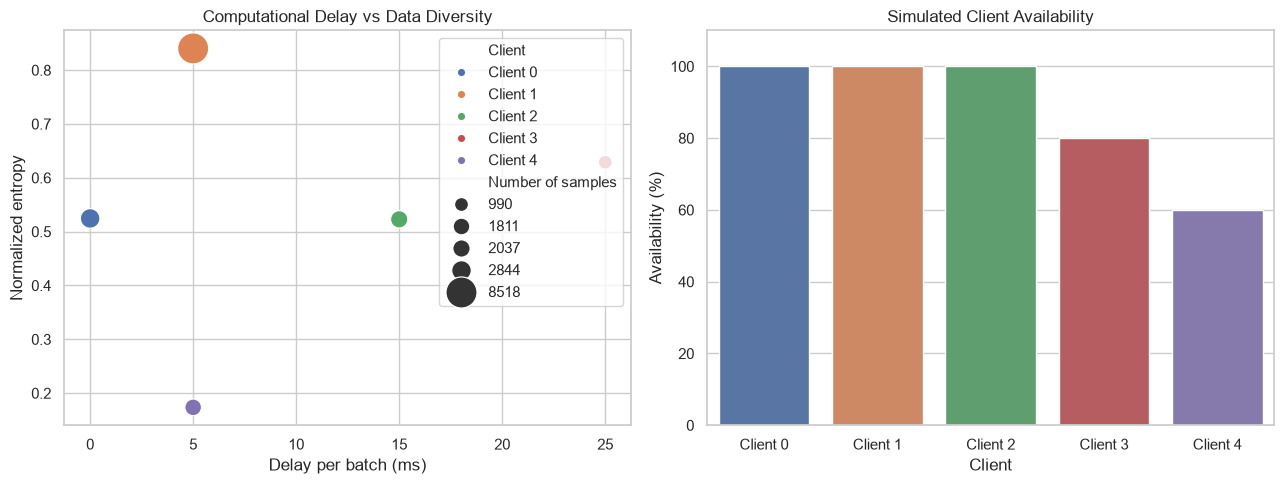

: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=client_profile,
    x="Delay per batch (ms)",
    y="Normalized entropy",
    size="Number of samples",
    hue="Client",
    sizes=(100, 500),
    ax=axes[0],
)

axes[0].set_title("Computational Delay vs Data Diversity")

sns.barplot(
    data=client_profile,
    x="Client",
    y="Availability (%)",
    hue="Client",
    legend=False,
    ax=axes[1],
)

axes[1].set_title("Simulated Client Availability")
axes[1].set_ylim(0, 110)

plt.tight_layout()
plt.show()

## 4. Summary and Research Observations

The EuroSAT training dataset contains 16,200 images distributed
across five federated clients using a Dirichlet partitioner
with alpha = 0.1.

The resulting partitions exhibit two forms of heterogeneity:

1. Quantity heterogeneity: client dataset sizes range from
   990 to 8,518 samples.

2. Label distribution heterogeneity: clients have different
   class distributions and normalized Shannon entropy values
   ranging from 0.174 to 0.840.

In addition, each client is assigned a simulated computational
profile with different processing delays and availability
probabilities.

These characteristics provide the experimental setting for
investigating resource-aware client selection.

The next stage will compare random selection, fastest-client
selection, and resource-aware selection while evaluating
model performance, training efficiency, participation fairness,
and class representation.